# 02 – Distributions and Outliers

**Objective:** analyse the distribution of the target (`PRICE`) and of the main numerical, categorical and binary features, detect outliers and erroneous extreme values, and decide how to treat them before modelling.

**Input:** `data/processed/listings_01.parquet` (output of notebook 01).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

try:
    df = pd.read_parquet("../data/processed/listings_01.parquet")
except FileNotFoundError:
    df = pd.read_csv("../data/Madrid_Sale.csv")

print(f"Loaded: {df.shape[0]} rows × {df.shape[1]} columns")

Loaded: 75803 rows × 39 columns


In [2]:
main_num_cols = ["PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
                 "FLOORCLEAN", "CADCONSTRUCTIONYEAR", "CADMAXBUILDINGFLOOR",
                 "CADDWELLINGCOUNT", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

df[main_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
PRICE,75803.0,389546.706595,413099.589385,21000.000000,157000.000000,257000.000000,457000.000000,8.133000e+06
CONSTRUCTEDAREA,75803.0,100.250056,66.469752,21.000000,62.000000,82.000000,115.000000,9.850000e+02
ROOMNUMBER,75803.0,2.567840,1.185249,0.000000,2.000000,3.000000,3.000000,1.000000e+01
BATHNUMBER,75803.0,1.564925,0.795319,0.000000,1.000000,1.000000,2.000000,5.000000e+00
FLOORCLEAN,75803.0,2.714510,2.211468,-1.000000,1.000000,2.000000,4.000000,1.100000e+01
CADCONSTRUCTIONYEAR,75803.0,1965.465918,28.921683,1623.000000,1955.000000,1967.000000,1983.000000,2.018000e+03
CADMAXBUILDINGFLOOR,75803.0,6.360672,2.842866,0.000000,5.000000,6.000000,8.000000,2.600000e+01
CADDWELLINGCOUNT,75803.0,38.716647,53.319922,1.000000,12.000000,21.000000,39.000000,1.499000e+03
DISTANCE_TO_CITY_CENTER,75803.0,4.476751,2.671328,0.015374,2.403653,4.114290,6.219253,1.415881e+01
DISTANCE_TO_METRO,75803.0,0.470108,0.595171,0.001416,0.212755,0.330015,0.519178,9.344541e+00


## 1. Target variable: `PRICE`

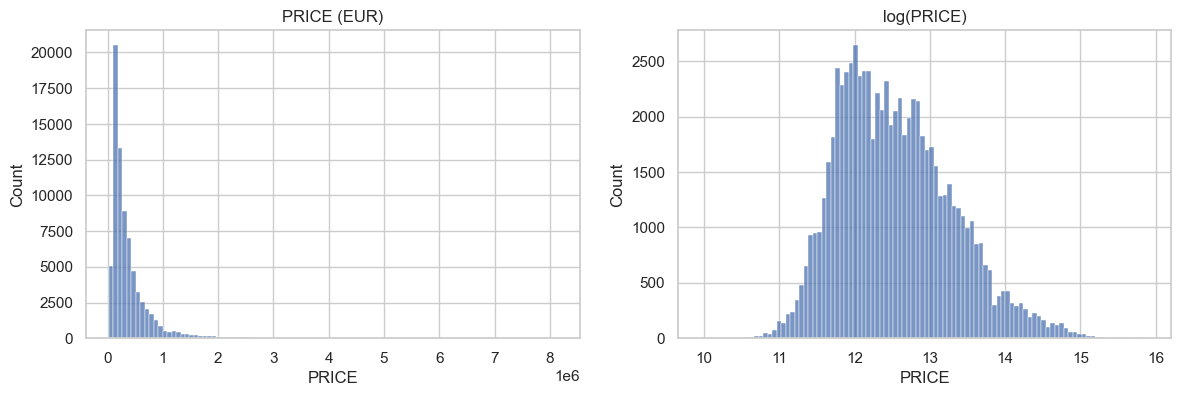

Skewness PRICE:      4.07
Skewness log(PRICE): 0.54


In [3]:
price = df["PRICE"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(price, bins=100, ax=axes[0])
axes[0].set_title("PRICE (EUR)")
sns.histplot(np.log(price), bins=100, ax=axes[1])
axes[1].set_title("log(PRICE)")
plt.show()

print(f"Skewness PRICE:      {price.skew():.2f}")
print(f"Skewness log(PRICE): {np.log(price).skew():.2f}")

The raw sale price is strongly right-skewed: most properties are priced below 500,000 EUR, but a few reach several million. After a log transformation the distribution becomes approximately symmetric. **Conclusion:** the model should predict `log(PRICE)` instead of `PRICE`, and outliers should be evaluated on the log scale.

In [4]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_bounds(price)
n_out = ((price < low) | (price > high)).sum()
print(f"IQR on PRICE:      [{low:,.0f}, {high:,.0f}] EUR  -> {n_out:,} outliers ({n_out/len(price):.1%})")

log_price = np.log(price)
log_low, log_high = iqr_bounds(log_price)
n_out_log = ((log_price < log_low) | (log_price > log_high)).sum()
print(f"IQR on log(PRICE): [{np.exp(log_low):,.0f}, {np.exp(log_high):,.0f}] EUR  -> {n_out_log:,} outliers ({n_out_log/len(price):.1%})")

IQR on PRICE:      [-293,000, 907,000] EUR  -> 5,518 outliers (7.3%)
IQR on log(PRICE): [31,614, 2,269,557] EUR  -> 681 outliers (0.9%)


In [5]:
# Inspect extreme prices using 3·IQR on the log scale
log_low3, log_high3 = iqr_bounds(log_price, k=3)
upper_price = np.exp(log_high3)
lower_price = np.exp(log_low3)
print(f"Extreme-outlier thresholds (3·IQR on log scale): [{lower_price:,.0f}, {upper_price:,.0f}] EUR")

extreme_high = df[df["PRICE"] > upper_price]
extreme_low = df[df["PRICE"] < lower_price]
print(f"\nListings above {upper_price:,.0f} EUR: {len(extreme_high)}")
print(f"Listings below {lower_price:,.0f} EUR: {len(extreme_low)}")

print(f"\n--- Extreme high prices ---")
print(extreme_high[["PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
                     "CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER"]].describe())

Extreme-outlier thresholds (3·IQR on log scale): [6,366, 11,271,088] EUR

Listings above 11,271,088 EUR: 0
Listings below 6,366 EUR: 0

--- Extreme high prices ---
       PRICE  CONSTRUCTEDAREA  ROOMNUMBER  BATHNUMBER  CADCONSTRUCTIONYEAR  \
count    0.0              0.0         0.0         0.0                  0.0   
mean     NaN              NaN         NaN         NaN                  NaN   
std      NaN              NaN         NaN         NaN                  NaN   
min      NaN              NaN         NaN         NaN                  NaN   
25%      NaN              NaN         NaN         NaN                  NaN   
50%      NaN              NaN         NaN         NaN                  NaN   
75%      NaN              NaN         NaN         NaN                  NaN   
max      NaN              NaN         NaN         NaN                  NaN   

       DISTANCE_TO_CITY_CENTER  
count                      0.0  
mean                       NaN  
std                        NaN  
m

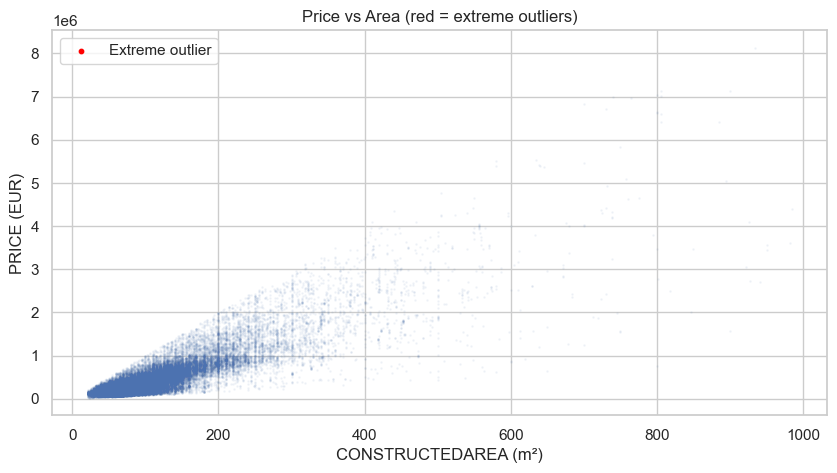

Median EUR/m² (all):              3,448
Median EUR/m² (extreme high):     nan


In [6]:
# Check if extreme high prices are justified by area
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df["CONSTRUCTEDAREA"], df["PRICE"], alpha=0.05, s=1)
ax.scatter(extreme_high["CONSTRUCTEDAREA"], extreme_high["PRICE"], c="red", s=10, zorder=5, label="Extreme outlier")
ax.set_xlabel("CONSTRUCTEDAREA (m²)")
ax.set_ylabel("PRICE (EUR)")
ax.set_title("Price vs Area (red = extreme outliers)")
ax.legend()
plt.show()

# Price per m² for extreme outliers vs rest
print(f"Median EUR/m² (all):              {(df['PRICE'] / df['CONSTRUCTEDAREA']).median():,.0f}")
print(f"Median EUR/m² (extreme high):     {(extreme_high['PRICE'] / extreme_high['CONSTRUCTEDAREA']).median():,.0f}")

### Decision on price outliers

- **Extreme high prices are luxury properties, not errors.** Unlike the Airbnb dataset where extreme prices were placeholders, here the most expensive listings tend to have large areas, prime locations, and high price-per-m² consistent with luxury real estate in central Madrid. They are real market data.
- **Action 1 – remove extreme outliers:** listings beyond the 3·IQR fence on the log scale are removed. These are the most extreme cases where the price is disproportionate even for the area, and they would distort the model.
- **Action 2 – keep moderate outliers:** the 1.5·IQR rule flags a larger set of properties. Many are legitimate large or central flats. Modelling `log(PRICE)` will naturally limit their influence.
- Applying the IQR rule to the raw price is not appropriate: the distribution is too skewed and it flags too many legitimate properties.

In [7]:
n_before = len(df)
df = df[~((df["PRICE"] > upper_price) | (df["PRICE"] < lower_price))]
print(f"Removed {n_before - len(df)} extreme price outliers (3·IQR on log scale)")
print(f"Shape: {df.shape}")

Removed 0 extreme price outliers (3·IQR on log scale)
Shape: (75803, 39)


## 2. Main numerical features

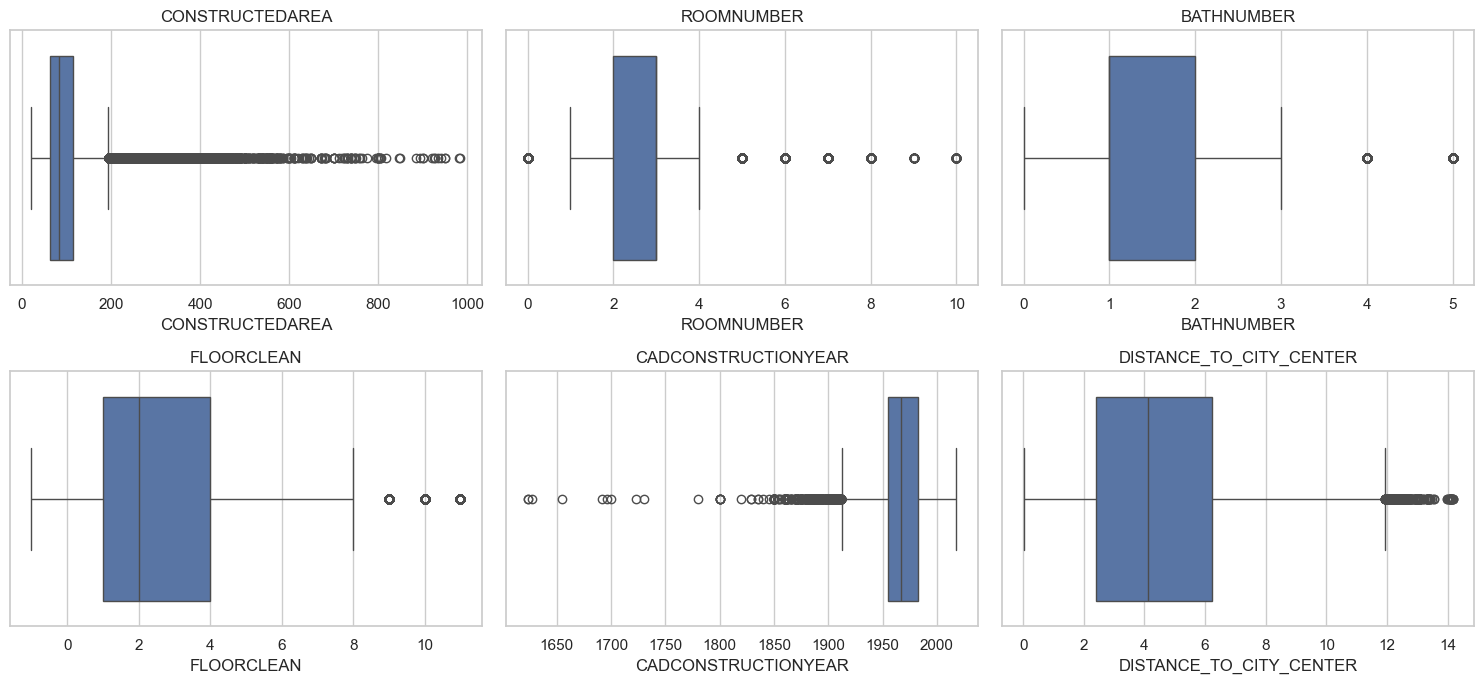

In [8]:
feat_cols = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "FLOORCLEAN",
             "CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Investigating extreme values before treating them

Before applying any treatment, we inspect which listings would be affected by each candidate rule.

Listings with CONSTRUCTEDAREA > 500 m²: 189
       CONSTRUCTEDAREA  ROOMNUMBER  BATHNUMBER         PRICE  \
count       189.000000  189.000000  189.000000  1.890000e+02   
mean        636.417989    5.608466    3.947090  3.249492e+06   
std         119.578826    2.341833    1.319798  1.558296e+06   
min         501.000000    0.000000    1.000000  4.880000e+05   
25%         548.000000    5.000000    3.000000  2.344000e+06   
50%         580.000000    6.000000    4.000000  3.039000e+06   
75%         720.000000    7.000000    5.000000  4.024000e+06   
max         985.000000   10.000000    5.000000  8.133000e+06   

       DISTANCE_TO_CITY_CENTER  
count               189.000000  
mean                  3.017960  
std                   2.003907  
min                   0.083329  
25%                   1.710670  
50%                   2.489297  
75%                   3.908721  
max                  10.908814  


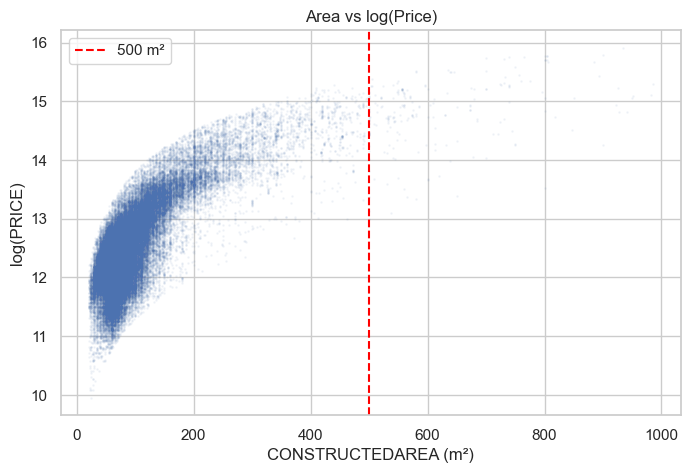

In [9]:
# CONSTRUCTEDAREA extremes
large = df[df["CONSTRUCTEDAREA"] > 500]
print(f"Listings with CONSTRUCTEDAREA > 500 m²: {len(large)}")
print(large[["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "PRICE", "DISTANCE_TO_CITY_CENTER"]].describe())

# Check if area and price are proportional for large properties
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["CONSTRUCTEDAREA"], np.log(df["PRICE"]), alpha=0.05, s=1)
ax.axvline(500, color="red", linestyle="--", label="500 m²")
ax.set_xlabel("CONSTRUCTEDAREA (m²)")
ax.set_ylabel("log(PRICE)")
ax.set_title("Area vs log(Price)")
ax.legend()
plt.show()

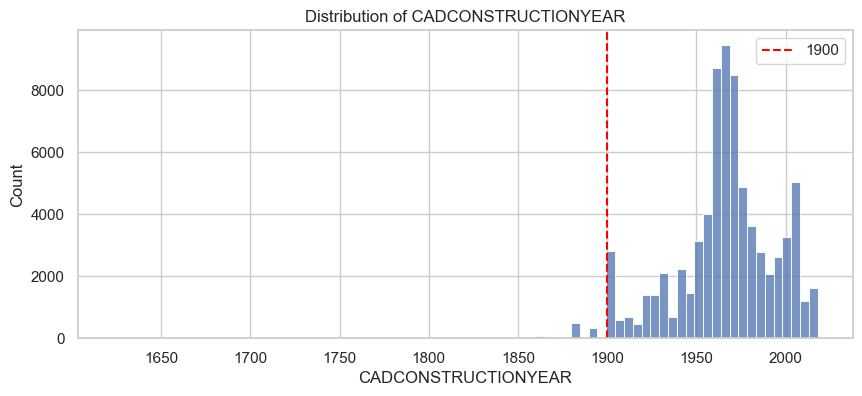

Buildings before 1900: 1096 (1.4%)
Median PRICE (pre-1900): 357,500 EUR
Median PRICE (1900+):    256,000 EUR


In [10]:
# CADCONSTRUCTIONYEAR distribution
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["CADCONSTRUCTIONYEAR"], bins=80, ax=ax)
ax.set_title("Distribution of CADCONSTRUCTIONYEAR")
ax.axvline(1900, color="red", linestyle="--", label="1900")
ax.legend()
plt.show()

old = df[df["CADCONSTRUCTIONYEAR"] < 1900]
print(f"Buildings before 1900: {len(old)} ({len(old)/len(df):.1%})")
print(f"Median PRICE (pre-1900): {old['PRICE'].median():,.0f} EUR")
print(f"Median PRICE (1900+):    {df[df['CADCONSTRUCTIONYEAR'] >= 1900]['PRICE'].median():,.0f} EUR")

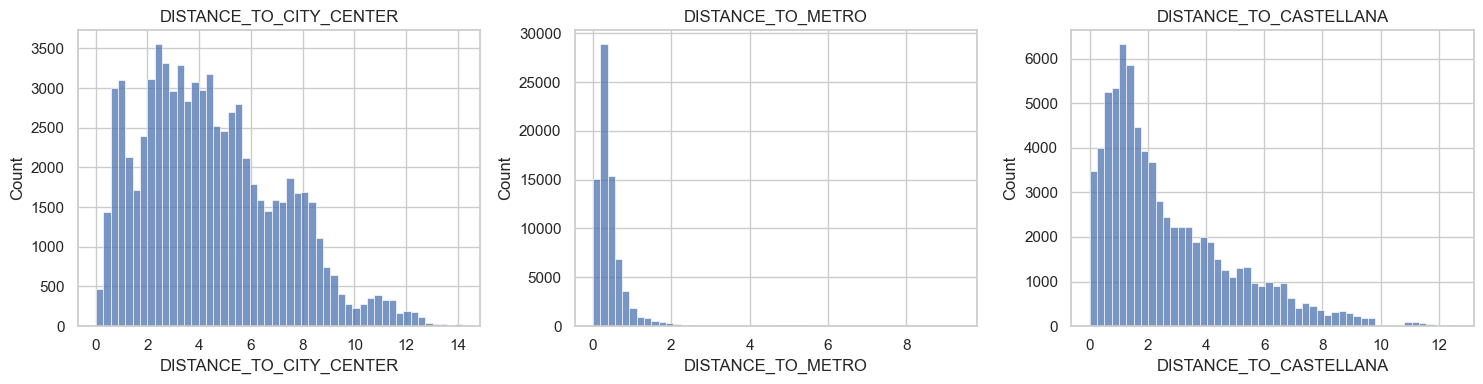

CADDWELLINGCOUNT > 500: 78 listings
       CADDWELLINGCOUNT  CADMAXBUILDINGFLOOR         PRICE
count         78.000000            78.000000  7.800000e+01
mean         607.474359             9.653846  5.964615e+05
std          130.127482             2.931366  2.114519e+05
min          501.000000             5.000000  7.500000e+04
25%          532.000000             8.000000  4.620000e+05
50%          574.000000             9.000000  5.655000e+05
75%          685.250000            14.000000  7.167500e+05
max         1499.000000            14.000000  1.372000e+06


In [11]:
# Distance features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO", "DISTANCE_TO_CASTELLANA"]):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# CADDWELLINGCOUNT
print(f"CADDWELLINGCOUNT > 500: {(df['CADDWELLINGCOUNT'] > 500).sum()} listings")
print(df[df["CADDWELLINGCOUNT"] > 500][["CADDWELLINGCOUNT", "CADMAXBUILDINGFLOOR", "PRICE"]].describe())

### Decisions on feature outliers

Each extreme value was inspected before deciding on a treatment:

- **`CONSTRUCTEDAREA` > 500 m²:** these are legitimate large properties (penthouses, mansions). Their price scales proportionally with area. **Action:** kept — they represent the luxury segment.
- **`CADCONSTRUCTIONYEAR` < 1900:** historic buildings in central Madrid. They have *higher* median prices than newer buildings (prime locations). **Action:** kept — they are real and informative.
- **Distance features:** smooth distributions with no suspicious spikes or gaps. **Action:** kept as-is.
- **`CADDWELLINGCOUNT` > 500:** large residential complexes. Plausible values for Madrid's large developments. **Action:** kept.
- **Capping at the 99th percentile was not applied.** Unlike the Airbnb dataset where hotel/hostel rooms had building-level data, here all features describe the property being sold, so extreme values reflect the actual market.

## 3. Categorical features

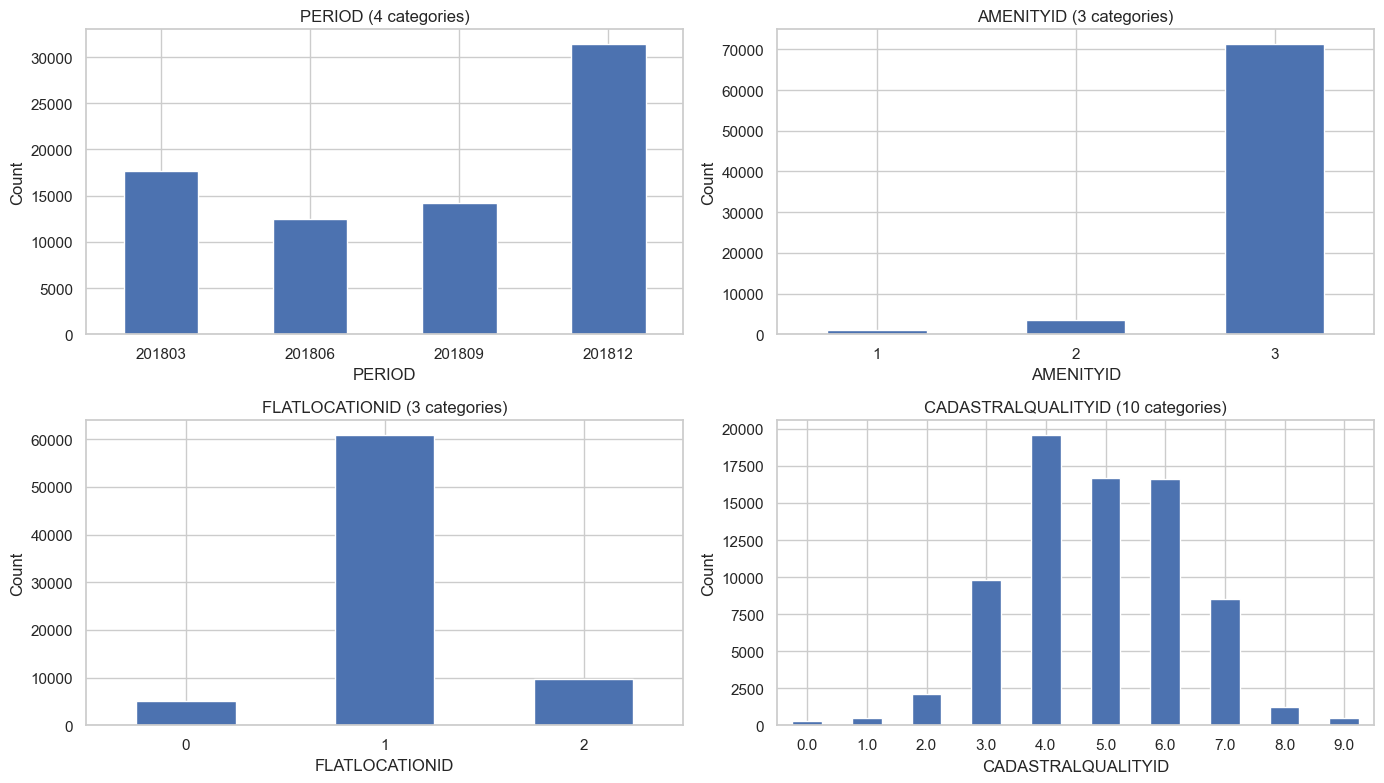


PERIOD:
PERIOD
201803    0.232
201806    0.165
201809    0.188
201812    0.414
Name: proportion, dtype: float64

AMENITYID:
AMENITYID
1    0.014
2    0.045
3    0.941
Name: proportion, dtype: float64

FLATLOCATIONID:
FLATLOCATIONID
0    0.068
1    0.804
2    0.128
Name: proportion, dtype: float64

CADASTRALQUALITYID:
CADASTRALQUALITYID
0.0    0.004
1.0    0.007
2.0    0.028
3.0    0.129
4.0    0.258
5.0    0.220
6.0    0.219
7.0    0.112
8.0    0.016
9.0    0.007
Name: proportion, dtype: float64


In [12]:
cat_cols = ["PERIOD", "AMENITYID", "FLATLOCATIONID", "CADASTRALQUALITYID"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    counts = df[col].value_counts().sort_index()
    counts.plot.bar(ax=ax)
    ax.set_title(f"{col} ({df[col].nunique()} categories)")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(normalize=True).sort_index().round(3))

### Findings on categorical features

- **`PERIOD`:** approximately balanced across the 4 quarters of 2018, with slightly more listings in Q2 (June) and Q3 (September).
- **`AMENITYID`:** three levels. Most properties are level 2 or 3. This ordinal variable captures the overall amenity quality and is kept as-is.
- **`FLATLOCATIONID`:** three values after imputation in notebook 01 (0 = unknown, 1 = interior, 2 = exterior). Exterior flats dominate.
- **`CADASTRALQUALITYID`:** 10 levels (0 = best, 9 = worst). Most properties cluster in the middle range (4–7). The distribution is not uniform, which is expected — there are more average buildings than luxury or very low-quality ones.

**No action needed** — the categorical features have reasonable distributions with no suspicious patterns.

## 4. Binary features distribution

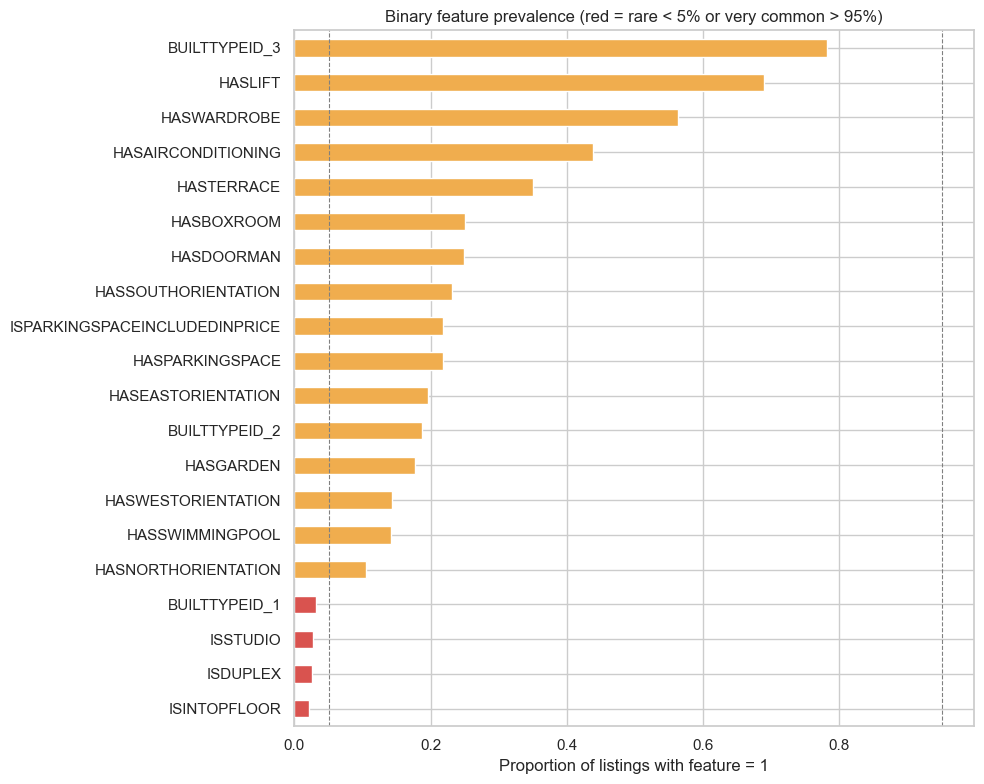

Rare features (< 5%):
ISINTOPFLOOR     0.022
ISDUPLEX         0.025
ISSTUDIO         0.027
BUILTTYPEID_1    0.032
dtype: float64

Very common features (> 95%):
Series([], dtype: float64)


In [13]:
binary_cols = [c for c in df.columns if c.startswith("HAS") or c.startswith("IS") or c.startswith("BUILTTYPEID")]

proportions = df[binary_cols].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#f0ad4e" if 0.05 < v < 0.95 else "#d9534f" for v in proportions]
proportions.plot.barh(ax=ax, color=colors)
ax.set_xlabel("Proportion of listings with feature = 1")
ax.set_title("Binary feature prevalence (red = rare < 5% or very common > 95%)")
ax.axvline(0.05, color="gray", linestyle="--", lw=0.8)
ax.axvline(0.95, color="gray", linestyle="--", lw=0.8)
plt.tight_layout()
plt.show()

print("Rare features (< 5%):")
print(proportions[proportions < 0.05].round(3))
print("\nVery common features (> 95%):")
print(proportions[proportions > 0.95].round(3))

### Findings on binary features

- Most binary features have reasonable prevalence (5%–95%), meaning they carry useful discriminative information.
- **Very rare features** (< 5%): features like `ISDUPLEX`, `ISSTUDIO`, `ISINTOPFLOOR` may apply to only a small fraction of listings. They are kept because even rare features can be highly predictive when present (e.g., a duplex or studio has a very different price profile).
- **Very common features** (> 95%): if any feature is almost always 1 (or 0), it has low variance and limited predictive power. These can be monitored during modelling.
- **No action needed** — all binary features are valid 0/1 values with no missing data or inconsistencies.

## Summary and next steps

**Actions performed in this notebook**

| Issue | Evidence | Action |
|---|---|---|
| PRICE strongly right-skewed | Log transformation normalises the distribution | Model `log(PRICE)` |
| Extreme price outliers (3·IQR on log scale) | Beyond the extreme-outlier fence | **Removed** |
| Moderate price outliers (1.5·IQR) | Legitimate luxury/affordable properties | Kept |
| `CONSTRUCTEDAREA` > 500 m² | Price proportional to area | Kept |
| `CADCONSTRUCTIONYEAR` < 1900 | Historic central buildings with high prices | Kept |
| Distance features | Smooth distributions | Kept |
| Categorical features (PERIOD, AMENITYID, etc.) | Balanced, no anomalies | Kept |
| Binary features | Valid 0/1, reasonable prevalence | Kept |

**Output:** saved to `data/processed/listings_02.parquet`.

**Key difference from the Airbnb dataset:** this dataset required far fewer corrections. The extreme prices here are real luxury properties (not placeholders), and the feature values are consistent with the properties being described. The main action was removing price outliers on the log scale.

In [14]:
df.to_parquet("../data/processed/listings_02.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 75803 rows × 39 columns
